# WattWise — Phase 4: The optimiser

**This is the heart of WattWise.** You tell it your appliances and their deadlines, and it returns the best half-hours to run each one — then shows the £ and CO₂ saved versus just running them at the 6pm peak.

The engine lives in `backend/optimisation/scheduler.py` (with unit tests in `backend/tests/`). This notebook just *uses* it on a real day of your data.

Run each cell with **Shift + Enter**.

## 1. Load the optimiser and one real day

We import the scheduler, then take the most recent full day from your `history.csv` (a complete 24 hours of real price + carbon) to schedule within.

In [1]:
import sys; sys.path.append("..")   # so we can import the backend package
import pandas as pd
import matplotlib.pyplot as plt
from backend.optimisation.scheduler import Appliance, schedule_appliance, run_at_fixed_hour

df = pd.read_csv("../backend/data/processed/history.csv", parse_dates=["timestamp_utc"])
local = df["timestamp_utc"].dt.tz_convert("Europe/London")
df["hour"] = local.dt.hour + local.dt.minute / 60
df["date"] = local.dt.date

# pick the most recent date that has a full 48 half-hour slots
counts = df.groupby("date").size()
full_day = counts[counts == 48].index[-1]
day = df[df["date"] == full_day].sort_values("hour").reset_index(drop=True)
print(f"Scheduling within {full_day} — {len(day)} half-hourly slots")
day[["hour", "price_p_kwh", "carbon_intensity"]].head()

Scheduling within 2026-11-02 — 48 half-hourly slots


,hour,price_p_kwh,carbon_intensity
0,0.0,36.35,125
1,0.5,36.88,121
2,1.0,36.83,116
3,1.5,35.93,112
4,2.0,36.35,107


## 2. Your four appliances

Each one: how much energy it needs, how powerful it is, and its window (earliest start → must-finish-by). **These numbers are illustrative** — swap in your own. The scheduler works out how many half-hour slots each run needs.

In [2]:
appliances = [
    Appliance("EV charge",       energy_kwh=10,  power_kw=7.0, earliest_hour=0,  deadline_hour=7),
    Appliance("Heat pump boost", energy_kwh=6,   power_kw=3.0, earliest_hour=0,  deadline_hour=24),
    Appliance("Dishwasher",      energy_kwh=1.2, power_kw=0.6, earliest_hour=0,  deadline_hour=7),
    Appliance("Washing machine", energy_kwh=1.0, power_kw=0.5, earliest_hour=8,  deadline_hour=22),
]
for a in appliances:
    print(f"{a.name:16s} needs {a.duration_slots} half-hour slots, done by {a.deadline_hour:.0f}:00")

EV charge        needs 3 half-hour slots, done by 7:00
Heat pump boost  needs 4 half-hour slots, done by 24:00
Dishwasher       needs 4 half-hour slots, done by 7:00
Washing machine  needs 4 half-hour slots, done by 22:00


## 3. The plan — and what it saves

For each appliance we pick the **balanced** best window (`lam=0.5`) and compare it to the lazy baseline: running everything at **6pm** (the dirtiest, dearest time).

In [3]:
def hhmm(h):
    return f"{int(h):02d}:{int(round((h % 1) * 60)):02d}"

plan_rows = []
tot_smart_p = tot_base_p = tot_smart_c = tot_base_c = 0
for a in appliances:
    smart = schedule_appliance(day, a, lam=0.5)
    base = run_at_fixed_hour(day, a, start_hour=18.0)
    tot_smart_p += smart["pounds"]; tot_base_p += base["pounds"]
    tot_smart_c += smart["kg_co2"]; tot_base_c += base["kg_co2"]
    plan_rows.append({
        "appliance": a.name,
        "run": f"{hhmm(smart['start_hour'])}-{hhmm(smart['end_hour'])}",
        "£": smart["pounds"], "kgCO2": smart["kg_co2"],
        "£ saved vs 6pm": round(base["pounds"] - smart["pounds"], 2),
        "kg saved vs 6pm": round(base["kg_co2"] - smart["kg_co2"], 2),
    })

plan = pd.DataFrame(plan_rows)
display(plan)
print(f"\nTotal for the day:  smart £{tot_smart_p:.2f} / {tot_smart_c:.2f} kg   "
      f"vs 6pm £{tot_base_p:.2f} / {tot_base_c:.2f} kg")
print(f"SAVED:  £{tot_base_p - tot_smart_p:.2f}  and  {tot_base_c - tot_smart_c:.2f} kg CO2  — in one day")

,appliance,run,£,kgCO2,£ saved vs 6pm,kg saved vs 6pm
0,EV charge,02:30-04:00,3.762,1.050,2.36,0.84
1,Heat pump boost,02:30-04:30,2.155,0.604,1.18,0.47
2,Dishwasher,02:30-04:30,0.431,0.121,0.24,0.09
3,Washing machine,10:30-12:30,0.355,0.136,0.20,0.04



Total for the day:  smart £6.70 / 1.91 kg   vs 6pm £10.68 / 3.36 kg
SAVED:  £3.98  and  1.45 kg CO2  — in one day


## 4. The dial — cheapest vs balanced vs greenest

The same appliance, scheduled three ways. This proves WattWise genuinely *trades off* cost and carbon (if they always agreed, all three rows would be identical) — which is exactly why the user gets a choice.

In [4]:
ev = appliances[0]
for lam, name in [(1.0, "cheapest"), (0.5, "balanced"), (0.0, "greenest")]:
    p = schedule_appliance(day, ev, lam=lam)
    print(f"{name:9s} (lam={lam}):  {hhmm(p['start_hour'])}-{hhmm(p['end_hour'])}   £{p['pounds']:.2f}   {p['kg_co2']:.2f} kg")

cheapest  (lam=1.0):  03:30-05:00   £3.72   1.13 kg
balanced  (lam=0.5):  02:30-04:00   £3.76   1.05 kg
greenest  (lam=0.0):  02:30-04:00   £3.76   1.05 kg


## 5. See the plan on the day

Price and carbon across the day, with each appliance's chosen run shaded. You should see the runs land in the cheap/green troughs and avoid the evening peak.

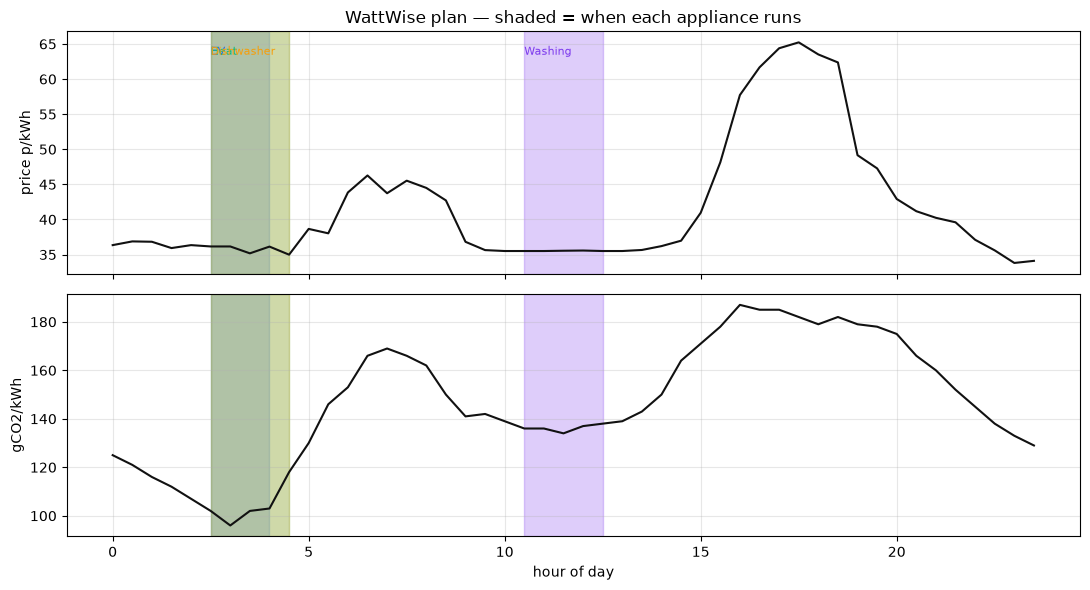

In [5]:
colors = ["#2563EB", "#10B981", "#F59E0B", "#7C3AED"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(day["hour"], day["price_p_kwh"], color="#111", lw=1.5); ax1.set_ylabel("price p/kWh"); ax1.grid(alpha=.3)
ax2.plot(day["hour"], day["carbon_intensity"], color="#111", lw=1.5); ax2.set_ylabel("gCO2/kWh"); ax2.set_xlabel("hour of day"); ax2.grid(alpha=.3)
for a, c in zip(appliances, colors):
    p = schedule_appliance(day, a, lam=0.5)
    for ax in (ax1, ax2):
        ax.axvspan(p["start_hour"], p["end_hour"], color=c, alpha=0.25)
    ax1.text(p["start_hour"], ax1.get_ylim()[1]*0.95, a.name.split()[0], fontsize=8, color=c)
ax1.set_title("WattWise plan — shaded = when each appliance runs")
plt.tight_layout(); plt.show()

## 6. Your finding ✍️

Write a sentence or two, e.g.:

> *On a real day, scheduling the four appliances into their best half-hours saved about £[...] and [...] kg CO₂ versus running them at 6pm — mostly by shifting to the overnight trough. The cheapest and greenest plans differed, confirming WattWise has to let the user choose. (Illustrative appliance specs; a shared household power limit and interruptible charging are the next upgrade, which is where a constraint solver like OR-Tools comes in.)*

**That's Phase 4 done ✅.** You now have the full WattWise loop: real data → explore → forecast → optimise → measure savings. Commit and push — then the remaining work is wiring it together and writing up.